# 1 · Supervised learning (behavioural cloning)

**Notebook 1 of 4** — SFT → REINFORCE → PPO → AlphaZero-style MCTS.

Before any reinforcement learning we teach a network to **copy a teacher**: a
scripted alpha-beta bot.  Every position from the teacher's games becomes a
labelled example *(board → move the teacher played, final result)* and we train
with ordinary cross-entropy.

| | |
|---|---|
| **Learns from** | someone else's moves (a fixed dataset) |
| **Signal per example** | the exact move to play — dense and low-noise |
| **Strength** | fast, stable, needs no game-playing during training |
| **Weakness** | can only approach the teacher; never sees its *own* mistakes (distribution shift) |

This notebook produces `checkpoints/sft.pt`, the starting point for notebooks 2–4.

**Runtime:** ~45 min the first time (most of it simulating the teacher's games), ~10 min after.

In [1]:
import sys, json, time, subprocess, sqlite3
from pathlib import Path
import numpy as np, chess, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "train" else Path.cwd().resolve()

def rel(p):
    """Path relative to the repo root (keeps absolute home paths out of outputs)."""
    p = Path(p).resolve()
    return str(p.relative_to(ROOT)) if ROOT in p.parents else str(p)
sys.path.insert(0, str(ROOT / "train"))
from chesslib import encoding as enc
from chesslib.model import ChessNet, masked_log_softmax, count_params, default_device, save_checkpoint
from chesslib.data import load_games, build_dataset, split_by_game, iterate_batches, DEFAULT_DB
from chesslib.arena import play_match

DEVICE = default_device()
CKPT_DIR = ROOT / "train" / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
RESULTS = ROOT / "train" / "results"; RESULTS.mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE, "| db:", rel(DEFAULT_DB))

device: mps | db: data/chess.db


## 1 · The teacher and its games

The bots live in `backend/app/bots/`. Measured against each other and against
Stockfish with `UCI_LimitStrength` (see the evaluation cell at the end of this
notebook and `train/results/`):

| bot | what it does | time / move |
|---|---|---|
| `random` | uniform random legal move | — |
| `heuristic` | 1-ply: grab the most material, random tie-break | <1 ms |
| `ab1`…`ab3` | alpha-beta search to depth 1–3 + capture search, material + piece-square tables | 5 / 22 / 100 ms |

We clone **`ab2`**: it is clearly stronger than `ab1`, decisive (few draws), and
fast enough to simulate thousands of games.  Its root move has a little random
noise (±10 centipawns) so games don't repeat, and every game starts with 6
random plies for variety.

> **Lesson learned the hard way.** A teacher must actually *prefer* a move.  The
> original `heuristic` bot scored most moves identically (it only counts
> material) and then always played the first move in generation order — so the
> network learned python-chess's move ordering, not chess.

The cell below simulates games only if the database has fewer than
`TARGET_GAMES` of them (via `train/generate_games.py`, parallel workers).

In [2]:
TEACHER = "ab2"
TARGET_GAMES = 6000

def count_games(name):
    with sqlite3.connect(DEFAULT_DB) as db:
        return db.execute("SELECT COUNT(*) FROM games WHERE white_player=? AND black_player=? "
                          "AND source='simulation' AND result IS NOT NULL", (name, name)).fetchone()[0]

have = count_games(TEACHER)
print(f"{have} {TEACHER}-vs-{TEACHER} games in the DB")
if have < TARGET_GAMES:
    cmd = [sys.executable, str(ROOT / "train" / "generate_games.py"), "--white", TEACHER, "--black", TEACHER,
           "--games", str(TARGET_GAMES - have), "--workers", "8", "--random-opening-plies", "6",
           "--seed", str(have + 1)]
    print("running:", " ".join(cmd[1:]))
    subprocess.run(cmd, check=True)
    print(f"now {count_games(TEACHER)} games")

6000 ab2-vs-ab2 games in the DB


## 2 · From database rows to (position, move) pairs

The `positions` table stores one row per ply with the FEN **after** the move:

| move_number | fen | move_uci |
|---|---|---|
| 0 | start position | NULL |
| 1 | position after 1.e4 | e2e4 |
| 2 | position after 1…e5 | e7e5 |

The label for "position *k*" is the move in row *k + 1*.  Pairing a row's FEN
with its own `move_uci` silently trains the network to guess **the move that was
just played** — an easy, useless task that still reaches high "accuracy".  We
avoid this by replaying each game's move list from the start, which also gives
the encoder real move history (needed for the repetition planes).

In [3]:
games = load_games(players=[TEACHER])
print(f"{len(games)} games, {sum(len(g.moves) for g in games):,} positions")
results = {}
for g in games: results[g.result] = results.get(g.result, 0) + 1
print("results:", results)

# Sanity check of the pairing: every label must be a legal move in its position.
g = games[0]; b = chess.Board(); ok = 0
for u in g.moves:
    ok += chess.Move.from_uci(u) in b.legal_moves; b.push_uci(u)
print(f"game {g.id}: {ok}/{len(g.moves)} labels legal")

6000 games, 746,155 positions
results: {'0-1': 2532, '1-0': 2949, '1/2-1/2': 519}
game 6352: 58/58 labels legal


## 3 · State and action encoding

Everything is encoded **from the side to move's point of view** — for Black the
board is mirrored and colours swapped — so the network learns one game, not two.
21 planes of 8×8:

* 0–5 our pieces, 6–11 their pieces
* 12–13 repetition counters (the old 14-plane encoding couldn't see repetitions,
  yet most of its games ended in repetition draws)
* 14–17 castling rights, 18 en-passant square, 19 50-move counter, 20 constant 1s

Moves become one of `ACTION_SIZE = 4168` indices: `from*64 + to` (4096) plus 72
slots for under-promotions.  The network outputs a logit for every index; at
play time we only ever softmax over the **legal** ones.

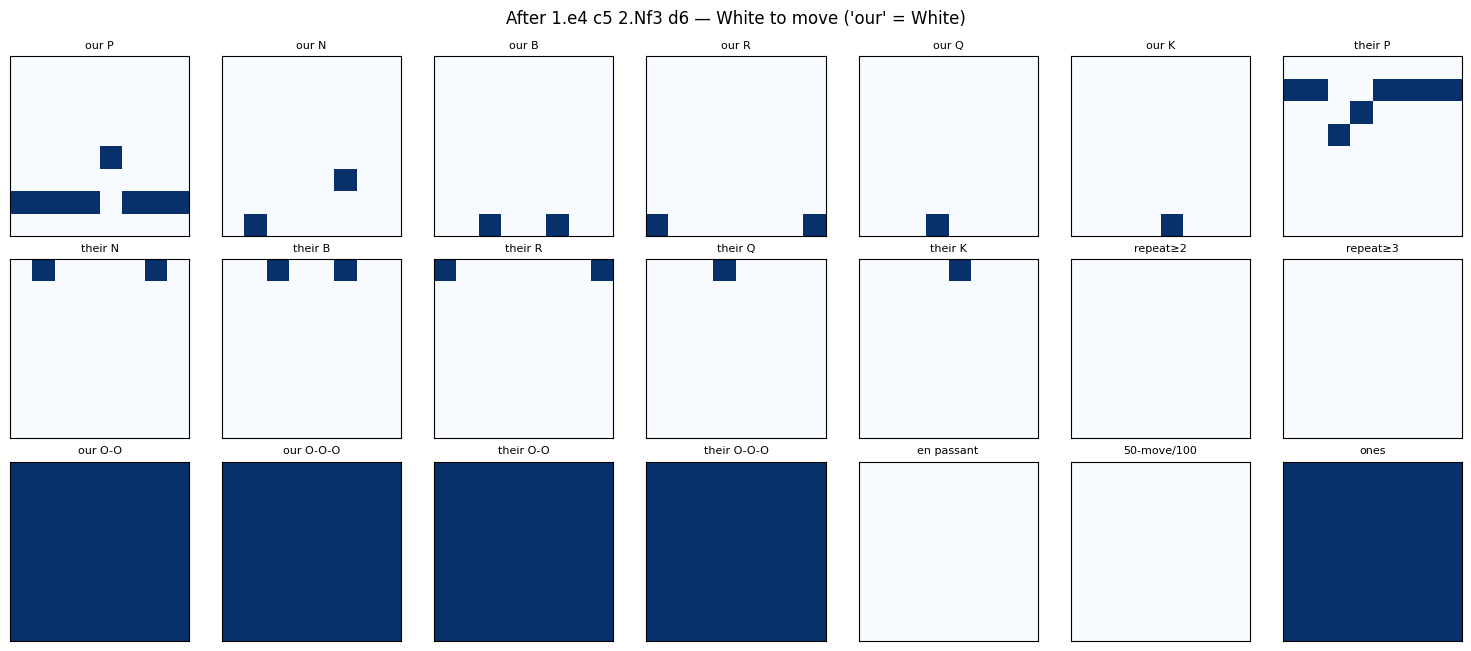

28 legal moves, e.g. [('f3g5', 1382), ('f3e5', 1380), ('f3h4', 1375), ('f3d4', 1371), ('f3g1', 1350)]


In [4]:
b = chess.Board()
for u in ["e2e4", "c7c5", "g1f3", "d7d6"]: b.push_uci(u)
planes = enc.encode_board(b)
names = ["our P","our N","our B","our R","our Q","our K","their P","their N","their B","their R","their Q","their K",
         "repeat≥2","repeat≥3","our O-O","our O-O-O","their O-O","their O-O-O","en passant","50-move/100","ones"]
fig, axes = plt.subplots(3, 7, figsize=(15, 6.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(enc.planes_to_float(planes)[i], cmap="Blues", vmin=0, vmax=1, origin="lower")
    ax.set_title(names[i], fontsize=8); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("After 1.e4 c5 2.Nf3 d6 — White to move ('our' = White)"); plt.tight_layout(); plt.show()

moves, idx = enc.legal_moves_and_indices(b)
print(f"{len(moves)} legal moves, e.g.", [(m.uci(), int(i)) for m, i in list(zip(moves, idx))[:5]])

In [5]:
CACHE = ROOT / "data" / f"sft_{TEACHER}_{len(games)}.npz"
if CACHE.exists():
    from chesslib.data import load_arrays; data = load_arrays(CACHE)
else:
    from chesslib.data import save_arrays
    data = build_dataset(games, workers=8); save_arrays(CACHE, data)
train_idx, val_idx = split_by_game(data, val_fraction=0.05, seed=0)
N = len(data["actions"])
print(f"{N:,} positions | train {len(train_idx):,} | val {len(val_idx):,} (split by game)")
print("value targets (side to move):", {k: f"{(data['wdl']==i).mean():.1%}" for i, k in enumerate(["win", "draw", "loss"])})

encoding games:   0%|          | 0/6000 [00:00<?, ?it/s]

746,155 positions | train 708,513 | val 37,642 (split by game)
value targets (side to move): {'win': '43.3%', 'draw': '13.7%', 'loss': '42.9%'}


## 4 · The network

A small residual tower (6 blocks × 64 filters, ~0.5 M parameters) with two heads:

* **policy** – logits over 4168 actions, scored as `query(from-square) · key(to-square)`;
* **value** – win/draw/loss probabilities for the side to move.

Small on purpose: notebook 4 runs this network tens of thousands of times per
second inside a tree search, so speed matters more than capacity here.

In [6]:
model = ChessNet(blocks=6, filters=64).to(DEVICE)
print(f"{count_params(model):,} parameters")

564,331 parameters


## 5 · Training

Loss per position:

$$\mathcal L = \underbrace{-\log \pi_\theta(a_{\text{teacher}}\mid s)}_{\text{policy: masked cross-entropy}} \;+\; c_v\,\underbrace{\mathrm{CE}(\text{WDL}_\theta(s),\ z)}_{\text{value}}$$

*Masked*: the softmax runs over legal moves only, so the network never spends
capacity learning that rooks don't move diagonally.  The value head learns from
the game result `z`, which is noisy for any single position (one blunder 40 moves
later flips it) — so we weight it at 0.5.

In [7]:
EPOCHS, BATCH, LR, VALUE_WEIGHT = 6, 512, 2e-3, 0.5
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
steps = EPOCHS * ((len(train_idx) + BATCH - 1) // BATCH)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)

def run_epoch(idx, train):
    model.train(train)
    tot = {"policy": 0.0, "value": 0.0, "top1": 0, "top3": 0, "n": 0}
    with torch.set_grad_enabled(train):
        for bt in iterate_batches(data, idx, BATCH, shuffle=train, device=DEVICE):
            logits, wdl = model(bt["x"])
            logp = masked_log_softmax(logits, bt["mask"])
            p_loss = F.nll_loss(logp, bt["action"])
            v_loss = F.cross_entropy(wdl, bt["wdl"])
            if train:
                opt.zero_grad(); (p_loss + VALUE_WEIGHT * v_loss).backward(); opt.step(); sched.step()
            n = len(bt["action"])
            top3 = logp.topk(3, dim=1).indices
            tot["policy"] += p_loss.item() * n; tot["value"] += v_loss.item() * n; tot["n"] += n
            tot["top1"] += (top3[:, 0] == bt["action"]).sum().item()
            tot["top3"] += (top3 == bt["action"][:, None]).any(1).sum().item()
    n = tot.pop("n")
    return {k: v / n for k, v in tot.items()}

history = []
for ep in range(1, EPOCHS + 1):
    t = time.time(); tr = run_epoch(train_idx, True); va = run_epoch(val_idx, False)
    history.append({"train": tr, "val": va})
    print(f"epoch {ep}: train policy {tr['policy']:.3f} top1 {tr['top1']:.1%} | "
          f"val policy {va['policy']:.3f} top1 {va['top1']:.1%} top3 {va['top3']:.1%} value {va['value']:.3f} "
          f"| {time.time()-t:.0f}s")

epoch 1: train policy 2.273 top1 30.8% | val policy 2.071 top1 35.2% top3 61.0% value 0.653 | 138s


epoch 2: train policy 2.005 top1 36.7% | val policy 1.974 top1 37.7% top3 63.8% value 0.643 | 143s


epoch 3: train policy 1.912 top1 38.7% | val policy 1.918 top1 38.9% top3 65.8% value 0.655 | 136s


epoch 4: train policy 1.830 top1 40.6% | val policy 1.850 top1 39.9% top3 67.0% value 0.670 | 134s


epoch 5: train policy 1.744 top1 42.8% | val policy 1.824 top1 40.7% top3 67.8% value 0.691 | 135s


epoch 6: train policy 1.670 top1 44.8% | val policy 1.823 top1 40.7% top3 68.0% value 0.702 | 115s


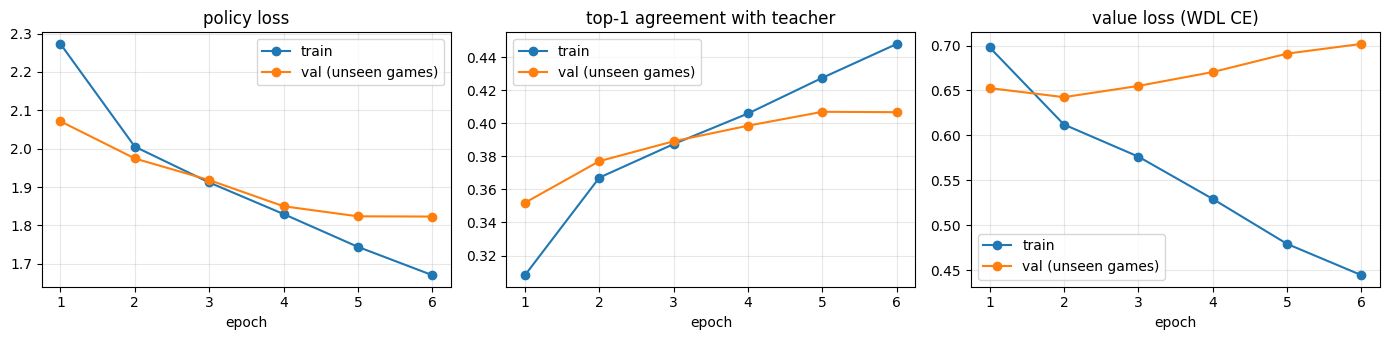

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
e = range(1, EPOCHS + 1)
for k, a, title in [("policy", ax[0], "policy loss"), ("top1", ax[1], "top-1 agreement with teacher"), ("value", ax[2], "value loss (WDL CE)")]:
    a.plot(e, [h["train"][k] for h in history], "o-", label="train")
    a.plot(e, [h["val"][k] for h in history], "o-", label="val (unseen games)")
    a.set_title(title); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6 · Accuracy is not strength — play games

Agreeing with the teacher 50% of the time says little about how well the
network *plays*: the other half of its moves may be blunders the teacher would
never make, and once it reaches positions the teacher never produced
(**distribution shift**), its errors compound.

So we play.  Every match uses paired random openings (each opening twice,
colours swapped), so games differ and the colour advantage cancels.

In [9]:
model.eval().cpu()
SFT_PATH = CKPT_DIR / "sft.pt"
save_checkpoint(SFT_PATH, model, notebook="chess_sft", teacher=TEACHER, games=len(games),
                positions=int(N), val_top1=history[-1]["val"]["top1"])
net = {"type": "policy", "checkpoint": str(SFT_PATH), "label": "SFT policy"}
matches = {}
for opp in [{"type": "random"}, {"type": "bot", "name": "heuristic"}, {"type": "bot", "name": "ab1"},
            {"type": "bot", "name": "ab2"}]:
    matches[opp.get("name", opp["type"])] = play_match(net, opp, n_games=60, workers=8, seed=1)

SFT policy vs random: +52 =8 -0 (score 93.3%, Elo diff +458 ± 324)


SFT policy vs heuristic: +46 =13 -1 (score 87.5%, Elo diff +338 ± 157)


SFT policy vs ab1: +5 =10 -45 (score 16.7%, Elo diff -280 ± 131)


SFT policy vs ab2: +2 =5 -53 (score 7.5%, Elo diff -436 ± 258)


### How much does a little search add?

The policy alone plays "by instinct".  Notebook 4 is about search; here is a
preview — the *same* network, now looking ahead with 100 MCTS simulations per
move (using its value head to judge positions):

In [10]:
mcts = {"type": "mcts", "checkpoint": str(SFT_PATH), "sims": 100, "label": "SFT + MCTS(100)"}
matches["mcts100_vs_ab2"] = play_match(mcts, {"type": "bot", "name": "ab2"}, n_games=40, workers=8, seed=2)

SFT + MCTS(100) vs ab2: +17 =9 -14 (score 53.8%, Elo diff +26 ± 112)


### Where does cloning fail?  Agreement by game phase

Teacher-agreement on unseen games, split by ply.  Openings are the most
predictable; later positions are more varied and the network has seen fewer
of each kind.

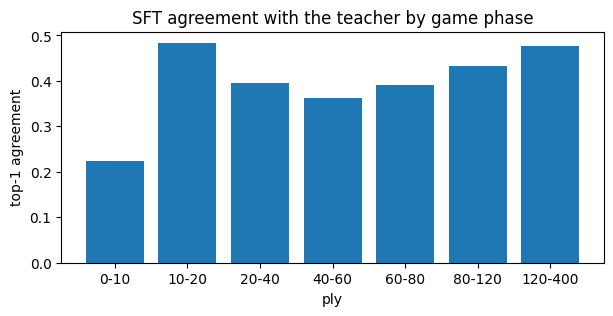

ChessNet(
  (stem): Sequential(
    (0): Conv2d(21, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (tower): Sequential(
    (0): ResBlock(
      (c1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (c2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ResBlock(
      (c1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (c2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affi

In [11]:
model.to(DEVICE)
bins = [0, 10, 20, 40, 60, 80, 120, 400]
ply = data["ply"][val_idx]; acc = []
for lo, hi in zip(bins[:-1], bins[1:]):
    sel = val_idx[(ply >= lo) & (ply < hi)]
    acc.append(run_epoch(sel, False)["top1"] if len(sel) else np.nan)
plt.figure(figsize=(7, 3)); plt.bar([f"{lo}-{hi}" for lo, hi in zip(bins[:-1], bins[1:])], acc)
plt.ylabel("top-1 agreement"); plt.xlabel("ply"); plt.title("SFT agreement with the teacher by game phase"); plt.show()
model.cpu()

In [12]:
summary = {"val_top1": history[-1]["val"]["top1"], "val_top3": history[-1]["val"]["top3"],
           "matches": {k: {"W": m.wins, "D": m.draws, "L": m.losses, "score": m.score} for k, m in matches.items()}}
(RESULTS / "sft.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "val_top1": 0.4067265288773179,
  "val_top3": 0.6800913872801658,
  "matches": {
    "random": {
      "W": 52,
      "D": 8,
      "L": 0,
      "score": 0.9333333333333333
    },
    "heuristic": {
      "W": 46,
      "D": 13,
      "L": 1,
      "score": 0.875
    },
    "ab1": {
      "W": 5,
      "D": 10,
      "L": 45,
      "score": 0.16666666666666666
    },
    "ab2": {
      "W": 2,
      "D": 5,
      "L": 53,
      "score": 0.075
    },
    "mcts100_vs_ab2": {
      "W": 17,
      "D": 9,
      "L": 14,
      "score": 0.5375
    }
  }
}


## 7 · Takeaways

**Strong**
* Dense supervision: every position carries an exact target, so a few epochs on
  one dataset give a competent policy *and* a value head that already knows
  material matters.
* Stable and cheap: no games are played during training.

**Weak**
* **Ceiling = teacher.**  We can at best imitate `ab2`; the network never learns
  *why* a move is good.
* **Distribution shift.** Training positions all come from the teacher's games.
  When the network's own mistakes lead elsewhere it has no data for it.
* **The value head overfits fast.** Every position of a game shares one
  result, so 700k positions are really only ~6k independent value labels —
  compare the train and val value loss above (val typically bottoms out after
  1–2 epochs while the policy keeps improving).
* **Bad labels are learned perfectly.** Garbage in (ties broken by move order,
  off-by-one pairings) → confident garbage out, with high "accuracy".

Next: **notebook 2 (REINFORCE)** stops imitating and learns from the network's
*own* games and their results.